<a href="https://colab.research.google.com/github/dheerajkumarrayala25-commits/Machine-learning-Project/blob/main/Course_Completion_Time_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name:R.Dheeraj kumar

# Course Completion Time Prediction for SkillBridge

## Objective

The objective of this project is to build a machine learning model that predicts the estimated number of days required for a learner to complete a SkillBridge course based on learner characteristics, study habits, previous performance, and engagement metrics.


## Data Source

The dataset is obtained from the YBI Foundation Project Dataset Repository It contains learner information such as age education level study hours quiz scores assignment submission rate and estimated course completion days

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

##purpose:
I used pandas to load and manipulate the dataset and numpy for numerical operations and
I used matplotlib to create graphs and seaborn for creating statistical visualizations

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

##Purpose
1)I used train_test_split to solits the dataset into training and testing sets.

2)labelencoder for converting text data into numbers.

3)linearRegression for building the prediction model.

4)metrics for evaluating the models performance.


##Import Data

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/YBIFoundation/MLProjectIdeas/main/Course%20Completion%20Time%20Prediction%20for%20SkillBridge.csv")

##Purpose
It helps us to upload csv file from the computer.
It reads the uploaded csv file and stores it in a dataframed named df

In [ ]:
df.head()

,gender,age,education_level,employed,internet_speed_mbps,previous_course_completion_rate,average_study_hours_per_week,quiz_score_average,video_watch_percentage,forum_participation_rate,assignment_submission_rate,estimated_completion_days
0,Male,31,Undergraduate,No,55.46,0.36,12.22,82.67,73.27,0.67,0.55,33.0
1,Other,22,High School,No,41.97,0.81,13.05,70.16,54.73,0.52,0.72,21.3
2,Male,51,Undergraduate,Yes,47.25,0.94,8.75,57.15,72.95,0.63,0.78,29.5
3,Male,16,Undergraduate,No,37.62,0.44,1.92,85.24,80.09,0.57,0.73,44.9
4,Male,27,Undergraduate,Yes,20.12,0.76,8.25,61.39,57.79,0.34,0.70,40.2


##purpose
It display the first five rows of the dataset

## Describe data


In [ ]:
df.shape

(1000, 12)

##Purpose:
It displays the number of no.of rows and columns are present in the dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   gender                           1000 non-null   object 
 1   age                              1000 non-null   int64  
 2   education_level                  1000 non-null   object 
 3   employed                         1000 non-null   object 
 4   internet_speed_mbps              1000 non-null   float64
 5   previous_course_completion_rate  1000 non-null   float64
 6   average_study_hours_per_week     1000 non-null   float64
 7   quiz_score_average               1000 non-null   float64
 8   video_watch_percentage           1000 non-null   float64
 9   forum_participation_rate         1000 non-null   float64
 10  assignment_submission_rate       1000 non-null   float64
 11  estimated_completion_days        1000 non-null   float64
dtypes: float64(8), int64(

##Purpose:
It displays the data types,column names and missing values

In [ ]:
df.describe()

,age,internet_speed_mbps,previous_course_completion_rate,average_study_hours_per_week,quiz_score_average,video_watch_percentage,forum_participation_rate,assignment_submission_rate,estimated_completion_days
count,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,37.045000,29.85440,0.647590,8.01612,74.305100,70.263080,0.484260,0.642620,38.129300
std,12.357657,10.09578,0.201607,2.93177,14.416189,17.339486,0.292404,0.200705,10.129324
min,16.000000,5.00000,0.300000,1.00000,50.020000,40.060000,0.000000,0.300000,15.000000
25%,27.000000,23.23250,0.470000,6.01000,61.890000,56.225000,0.220000,0.470000,31.000000
50%,36.000000,30.08000,0.655000,8.08500,73.985000,70.015000,0.485000,0.640000,38.300000
75%,48.000000,36.82000,0.810000,9.88000,86.832500,85.352500,0.730000,0.810000,45.000000
max,59.000000,58.82000,1.000000,18.29000,99.870000,99.930000,1.000000,1.000000,69.800000


##Purpose:
It displays statistical information for numerical columns

In [ ]:
df.columns

Index(['gender', 'age', 'education_level', 'employed', 'internet_speed_mbps',
       'previous_course_completion_rate', 'average_study_hours_per_week',
       'quiz_score_average', 'video_watch_percentage',
       'forum_participation_rate', 'assignment_submission_rate',
       'estimated_completion_days'],
      dtype='object')

##Purpose:
It displays the names of the columns in the dataset

In [ ]:
df.isnull().sum()

,0
gender,0
age,0
education_level,0
employed,0
internet_speed_mbps,0
previous_course_completion_rate,0
average_study_hours_per_week,0
quiz_score_average,0
video_watch_percentage,0
forum_participation_rate,0


##Purpose:
It checks for missing values in each column

## Data visualization

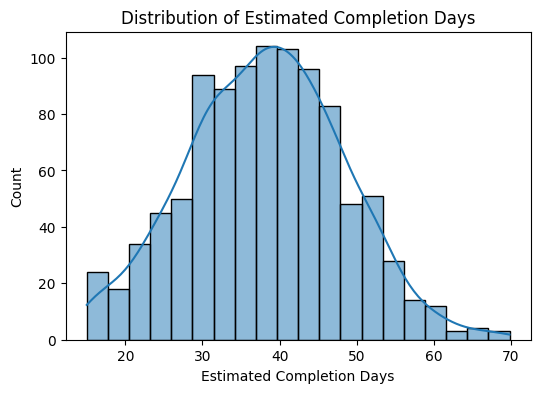

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df['estimated_completion_days'], bins=20, kde=True)
plt.title('Distribution of Estimated Completion Days')
plt.xlabel('Estimated Completion Days')
plt.ylabel('Count')
plt.show()

##Purpose:
It displays the distribution of the target varibale

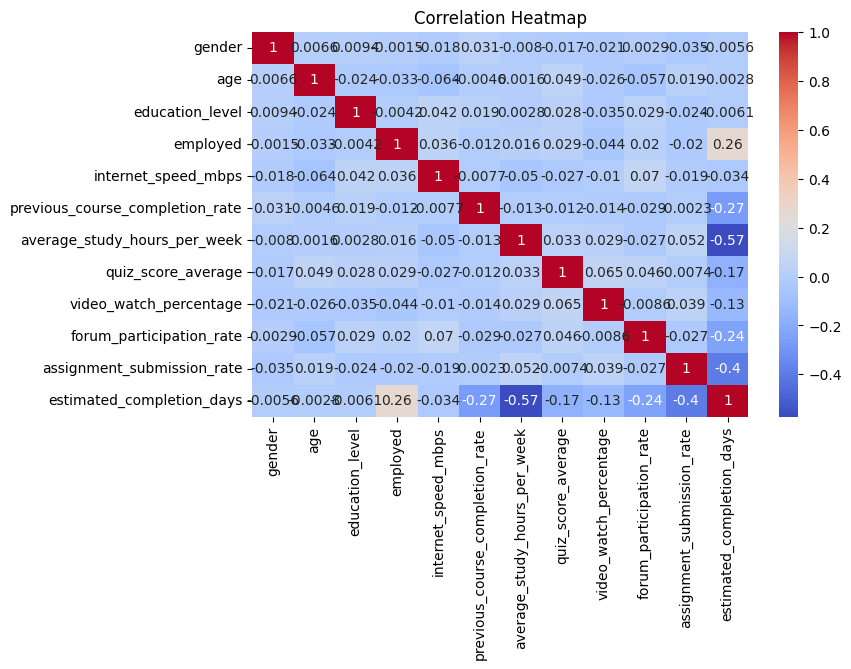

In [ ]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

##Purpose:
It helps us to identify the relatioship betwwen numerical variables and to understand which features are strongly correlated with the target variable

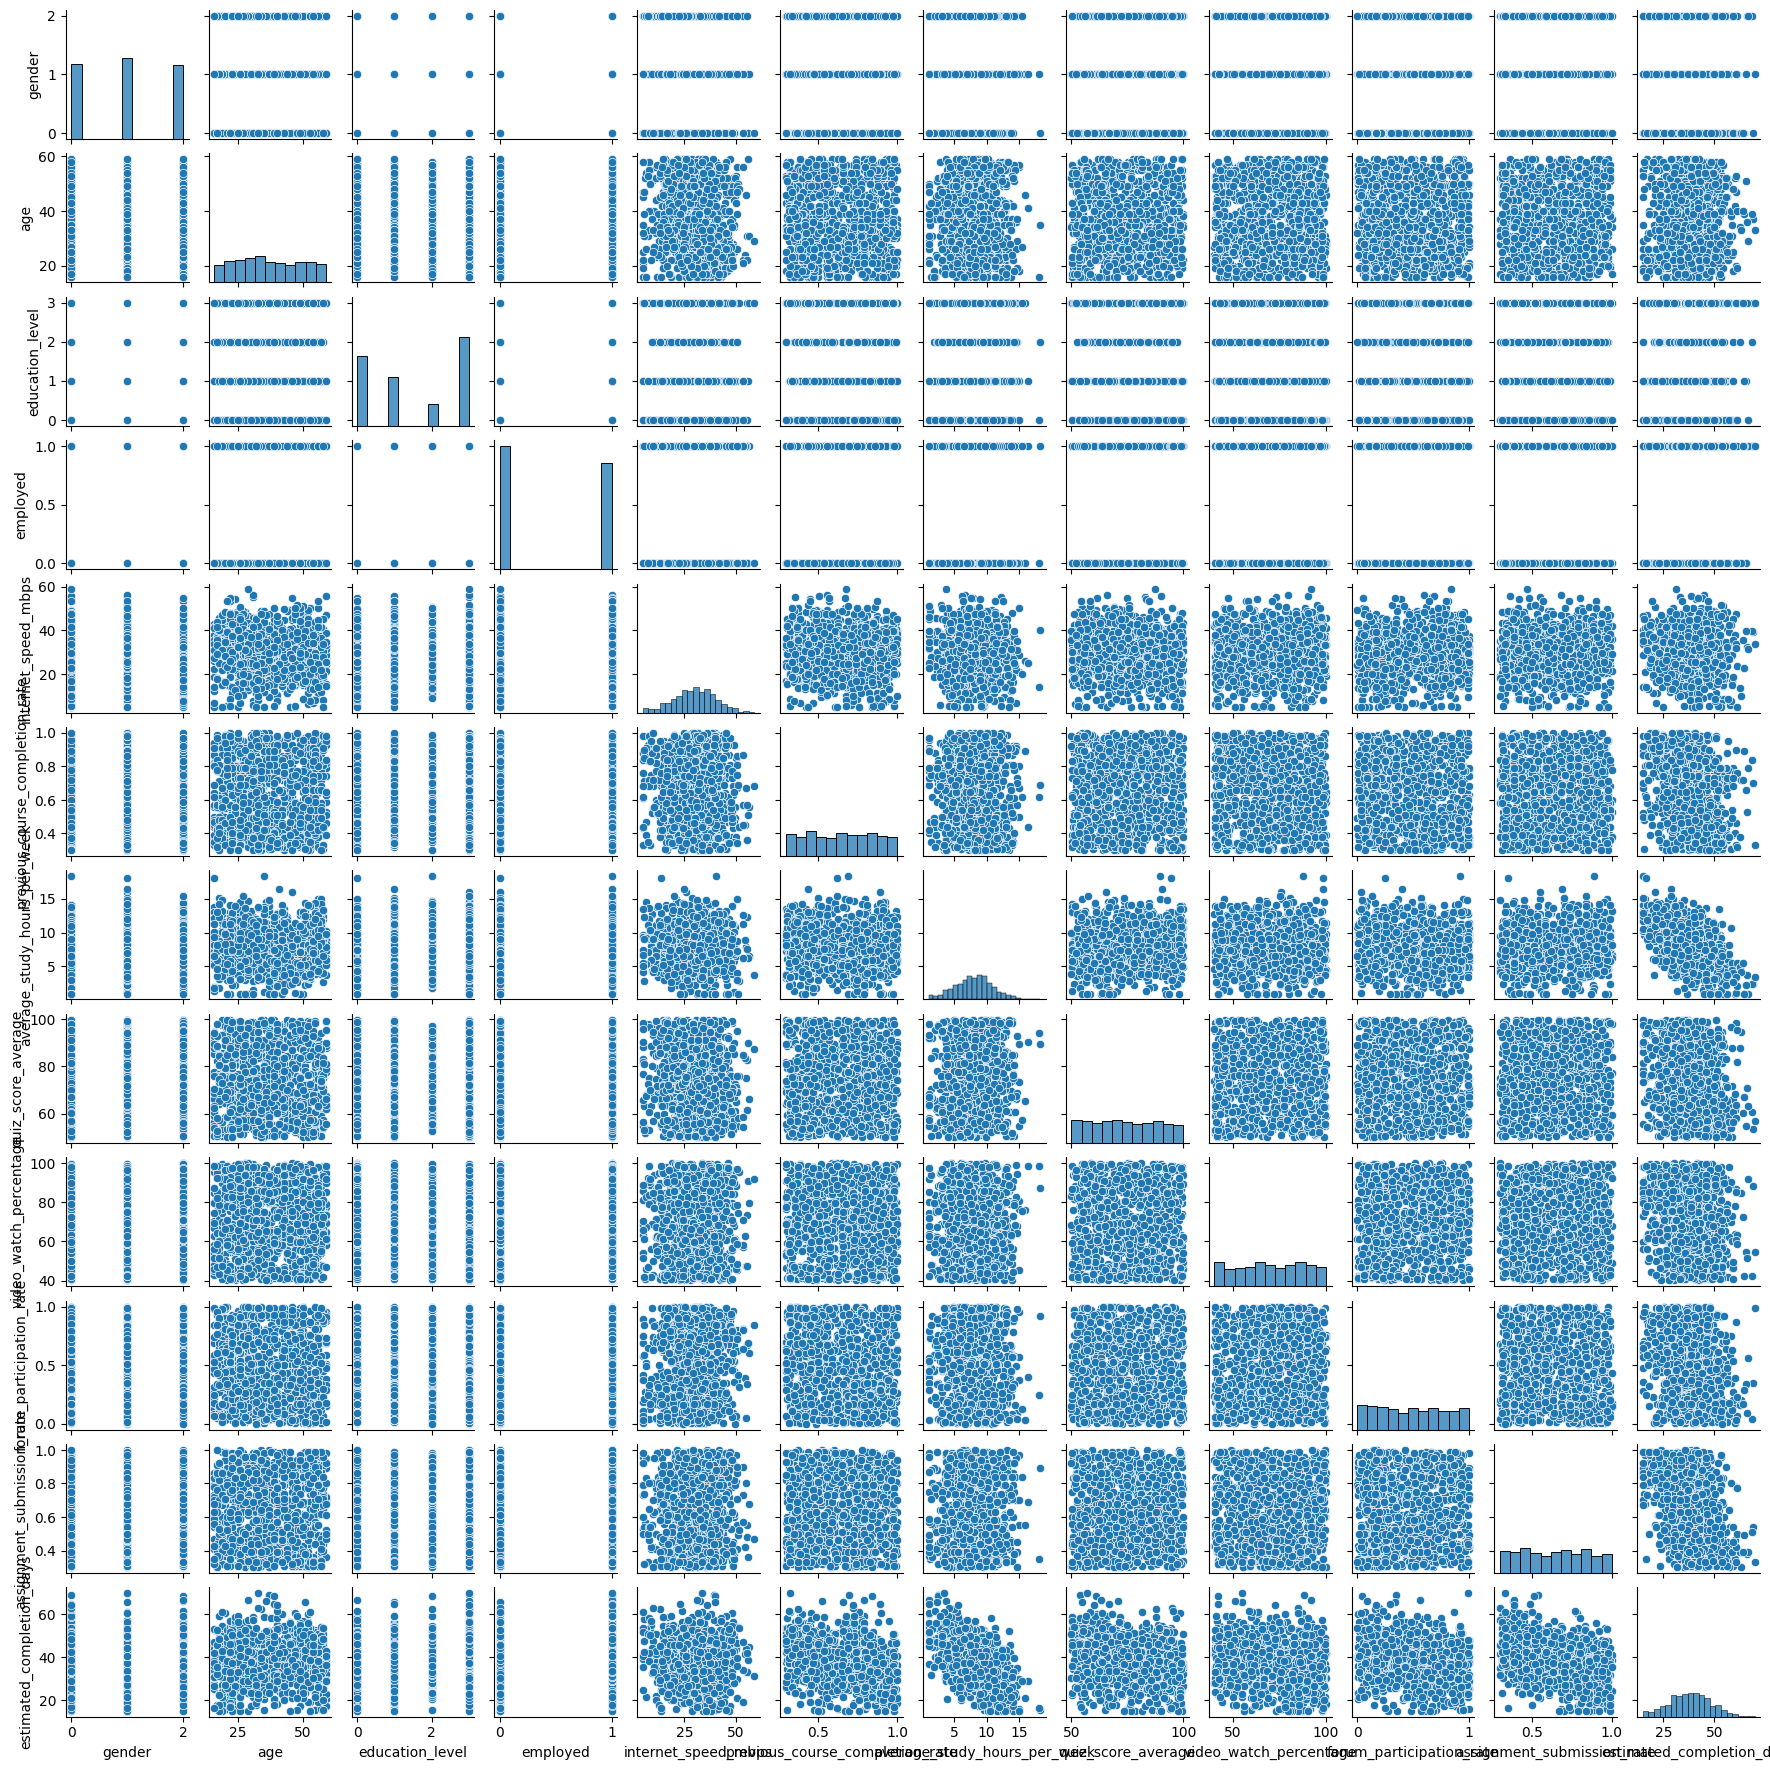

In [ ]:
sns.pairplot(df, height=1.5)
plt.show()

##Purpose:
It helps us to visualize the relationship between all numerical variables

##Data Preprocessing

In [ ]:
df.dtypes

,0
gender,object
age,int64
education_level,object
employed,object
internet_speed_mbps,float64
previous_course_completion_rate,float64
average_study_hours_per_week,float64
quiz_score_average,float64
video_watch_percentage,float64
forum_participation_rate,float64


##Purpose:
To identify the data types of each column and determine which Column need encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()

In [ ]:
df['gender'] = le.fit_transform(df['gender'])
df['education_level'] = le.fit_transform(df['education_level'])
df['employed'] = le.fit_transform(df['employed'])

In [ ]:
df.head()

,gender,age,education_level,employed,internet_speed_mbps,previous_course_completion_rate,average_study_hours_per_week,quiz_score_average,video_watch_percentage,forum_participation_rate,assignment_submission_rate,estimated_completion_days
0,1,31,3,0,55.46,0.36,12.22,82.67,73.27,0.67,0.55,33.0
1,2,22,1,0,41.97,0.81,13.05,70.16,54.73,0.52,0.72,21.3
2,1,51,3,1,47.25,0.94,8.75,57.15,72.95,0.63,0.78,29.5
3,1,16,3,0,37.62,0.44,1.92,85.24,80.09,0.57,0.73,44.9
4,1,27,3,1,20.12,0.76,8.25,61.39,57.79,0.34,0.70,40.2


##Purpose:
To convert categorical values into numerical values because machine learning algorithms cannot process text directly,so encodding is required

## Define Target Variable (y) and Feature Variables (X)

In [ ]:
X = df.drop('estimated_completion_days', axis=1)
y = df['estimated_completion_days']

##Purpose:
X contain all the independent features and Y contain the dependent variable to be predicted

## Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

##Purpose:
It splits the dataset into training and testing sets

## Model Training

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

##Purpose:
It creates and train the linear regression model using the training data

## Prediction

In [ ]:
y_pred = model.predict(X_test)

## Model Evaluation

In [ ]:
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error (MAE): 4.405936753530174
Mean Squared Error (MSE): 29.488640043802885
Root Mean Squared Error (RMSE): 5.43034437617016
R2 Score: 0.7123379381118342


##Purpose:
It evaluates the performance of the linear regression model using standard regression metrics

##Conclusion:
The Course Completion Time Prediction project successfully applied Linear Regression to estimate the time required to complete a course. After preprocessing the data and performing exploratory analysis, the model was trained and evaluated using standard regression metrics. The results indicate that Linear Regression provides a reasonable baseline for prediction. Further improvements in accuracy can be achieved by using advanced regression algorithms, feature engineering, and hyperparameter tuning.
